# EDA - ogłoszenia o naborach w służbie cywilnej (2018-2026)

Dane:
- 2018-2023: Beręsewicz, Wasiak, Walczak (2025), *Zbiór danych o naborach do polskiej służby cywilnej w latach 2018-2023*, RepOD, https://doi.org/10.18150/Q23MGT (CC BY 4.0), plik `data/jobs/kprm-job-ads-raw-data-2018-2023.csv`.
- od 14.12.2023: własne pobranie z nabory.kprm.gov.pl w tym samym formacie (`scripts/jobs/collect_full.py`), plik `data/jobs/kprm_2024_2026.csv`.

Kolumny `ad_result` nie używamy - mogą tam być nazwiska wybranych kandydatów (w naszym pobraniu jest pusta).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 150)
plt.rcParams["figure.figsize"] = (10, 4)

REPOD_PATH = Path("../data/jobs/kprm-job-ads-raw-data-2018-2023.csv")
KPRM_PATH = Path("../data/jobs/kprm_2024_2026.csv")
OUT = Path("../data/jobs/eda")
OUT.mkdir(parents=True, exist_ok=True)

CHATGPT = pd.Timestamp("2022-11-30")
SOURCE_SWITCH = pd.Timestamp("2023-12-14")  # pierwsze ogłoszenie z naszego pobrania
SEP = r"\|-\|"   # pozycje w tekstach są rozdzielone "|-|"

## Wczytanie i czyszczenie

In [2]:
repod = pd.read_csv(REPOD_PATH, low_memory=False).assign(zrodlo="RepOD")
kprm = pd.read_csv(KPRM_PATH, low_memory=False, encoding="utf-8-sig").assign(zrodlo="nabory.kprm.gov.pl")
print("RepOD:", repod.shape, "| nasze pobranie:", kprm.shape)
print("wspólne ad_id:", len(set(repod["ad_id"]) & set(kprm["ad_id"])))

raw = pd.concat([repod, kprm], ignore_index=True)
print(raw.shape)
print("duplikaty ad_id:", raw["ad_id"].duplicated().sum())

RepOD: (107260, 21) | nasze pobranie: (36419, 24)
wspólne ad_id: 1
(143679, 24)
duplikaty ad_id: 47


In [3]:
# braki osobno dla każdego źródła (url, template i fetched_at są tylko w naszym pobraniu)
(raw.drop(columns=["url", "template", "fetched_at"]).isna()
    .groupby(raw["zrodlo"]).mean().mul(100).round(1).T
    .sort_values("RepOD", ascending=False).head(5))

zrodlo,RepOD,nabory.kprm.gov.pl
ad_requirements2,0.4,25.8
ad_job_title,0.0,0.0
ad_institution,0.0,0.0
ad_city,0.0,70.0
ad_id,0.0,0.0


In [ ]:
# przy wspólnym ad_id zostaje wiersz z RepOD (jest pierwszy)
df = raw.drop(columns=["ad_result"]).drop_duplicates("ad_id").copy()
df["date"] = pd.to_datetime(df["ad_date_announced"], errors="coerce")
print(df["date"].min(), df["date"].max(), "| brak daty:", df["date"].isna().sum())

# 2017 to tylko listopad-grudzień, więc go pomijam
df = df[df["date"] >= "2018-01-01"].copy()
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.to_period("M")

# niepełne miesiące: koniec RepOD (XI-XII 2023, przed startem naszego pobrania) i ostatni miesiąc pobrania
INCOMPLETE = pd.PeriodIndex(["2023-11", "2023-12", str(df["month"].max())], freq="M")
print("niepełne miesiące:", list(INCOMPLETE.astype(str)))
df.groupby(["year", "zrodlo"]).size().unstack(fill_value=0)

2017-11-18 00:00:00 2026-10-15 00:00:00 | brak daty: 0
niepełne miesiące: ['2023-11', '2023-12', '2026-10']


zrodlo,RepOD,nabory.kprm.gov.pl
year,,
2018,19535,0
2019,18277,0
2020,13079,0
2021,16717,0
2022,21887,0
2023,15955,440
2024,0,14021
2025,0,12579
2026,0,9378


## Liczba ogłoszeń w czasie

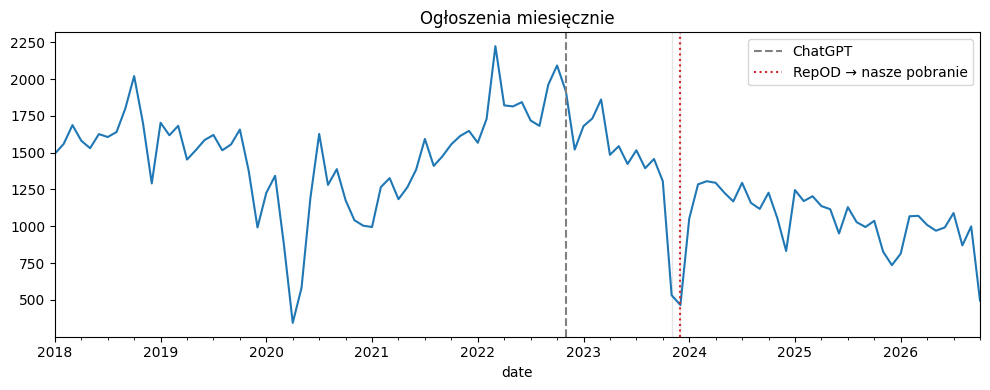

In [5]:
monthly = df.set_index("date").resample("MS").size()
ax = monthly.plot(title="Ogłoszenia miesięcznie")
ax.axvline(CHATGPT, color="grey", ls="--", label="ChatGPT")
ax.axvline(SOURCE_SWITCH, color="tab:red", ls=":", label="RepOD → nasze pobranie")
for month in INCOMPLETE:
    ax.axvspan(month.start_time, month.end_time, color="grey", alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "ogloszenia_miesiecznie.png", dpi=120)
plt.show()

## Teksty wymagań

Na przykładach widać, że `ad_requirements1` to wymagania niezbędne (są tam też formułki o obywatelstwie i niekaralności), a `ad_requirements2` to wymagania dodatkowe. Wykształcenie jest osobno w `ad_education`.

In [6]:
for _, r in df.sample(3, random_state=7).iterrows():
    print(r["ad_id"], r["date"].date(), r["ad_job_title"])
    print("  niezbędne:", str(r["ad_requirements1"])[:400])
    print("  dodatkowe:", str(r["ad_requirements2"])[:300], "\n")

145552 2024-11-29 główny specjalista
  niezbędne: Doświadczenie zawodowe co najmniej 3 lata w zakresie redagowania tekstów lub współpracy z mediami|-|Znajomość ustaw: Prawo o szkolnictwie wyższym i nauce, Prawo prasowe|-|Umiejęjętność redagowania i korekty tekstów|-|Umiejętność organizacji konferencji prasowych i współpracy z mediami|-|Rzetelność, organizacja pracy i orientacja na osiąganie celów, współpraca, komunikacja, kreatywność, samodzielno
  dodatkowe: Wykształcenie: wyższe z zakresu filologii polskiej lub dziennikarstwa 

70646 2020-10-30 główny specjalista
  niezbędne: doświadczenie zawodowe: w jednostkach budżetowych |-|znajomość zasad księgowości budżetowej|-|znajomość przepisów: kodeksu postępowania administracyjnego, ustawy o postępowaniu egzekucyjnym w administracji wraz z aktami wykonawczymi, ordynacji podatkowej, ustawy o rachunkowości, ustawy o finansach publicznych|-|umiejętności: współpracy, komunikacji, organizacji pracy, zorientowanie na osiąganie ce
  dodatkowe: W

In [7]:
def split_items(text):
    return [p.strip(" -;,.").lower() for p in re.split(SEP, str(text)) if len(p.strip()) > 3]

items = df["ad_requirements1"].apply(split_items).explode()
items.value_counts().head(20)

ad_requirements1
korzystanie z pełni praw publicznych                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 142803
nieskazanie prawomocnym wyrokiem za umyślne przestępstwo lub umyślne przestępstwo skarbowe                                                                                                                                                                                                                                                                                                 

In [8]:
# formułki ustawowe - nie liczę ich jako kompetencji
# "organ\w*" łapie "organach" (RepOD) i "organami" (formularz od 2023: "brak współpracy z organami ...")
BOILERPLATE = r"obywatelstw|pełni praw publicznych|nieskazan|organ\w* bezpieczeństwa|lustrac"

def n_items(text):
    return sum(not re.search(BOILERPLATE, p) for p in split_items(text))

df["n_niezbedne"] = df["ad_requirements1"].apply(n_items)
df["n_dodatkowe"] = df["ad_requirements2"].fillna("").apply(n_items)
df["n_zadania"] = df["ad_responsibilities"].apply(lambda t: len(split_items(t)))

n_by_year = df.groupby("year")[["n_niezbedne", "n_dodatkowe", "n_zadania"]].mean().round(2)
n_by_year

,n_niezbedne,n_dodatkowe,n_zadania
year,,,
2018,5.46,3.34,6.17
2019,5.49,3.34,6.25
2020,5.61,3.40,6.32
2021,5.77,3.44,6.49
2022,5.53,3.34,6.61
2023,5.75,3.31,6.45
2024,5.81,2.41,6.57
2025,5.93,2.44,6.55
2026,6.11,2.44,6.65


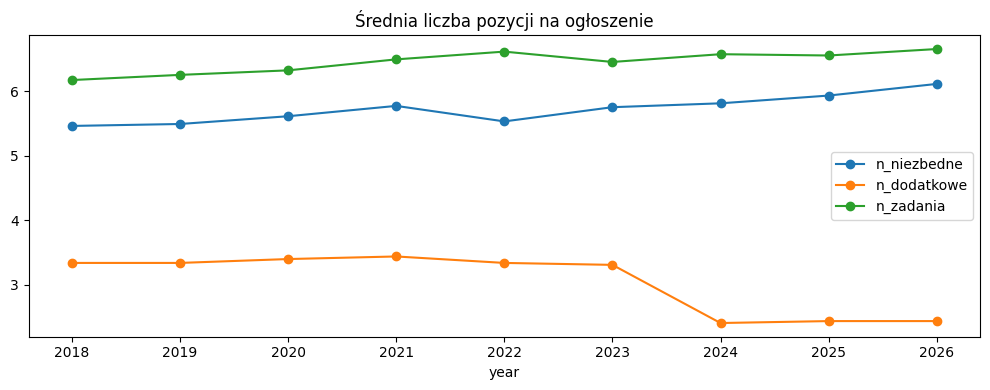

In [9]:
ax = n_by_year.plot(marker="o", title="Średnia liczba pozycji na ogłoszenie")
plt.tight_layout()
plt.savefig(OUT / "liczba_pozycji.png", dpi=120)
plt.show()

### Zgodność formatu na granicy źródeł

Od 14.12.2023 dane pochodzą z innego pobrania. Jeśli miary tekstu skaczą dokładnie na tej granicy, część zmiany może wynikać z pobierania, a nie z treści ogłoszeń. Szare pasy to niepełne miesiące.

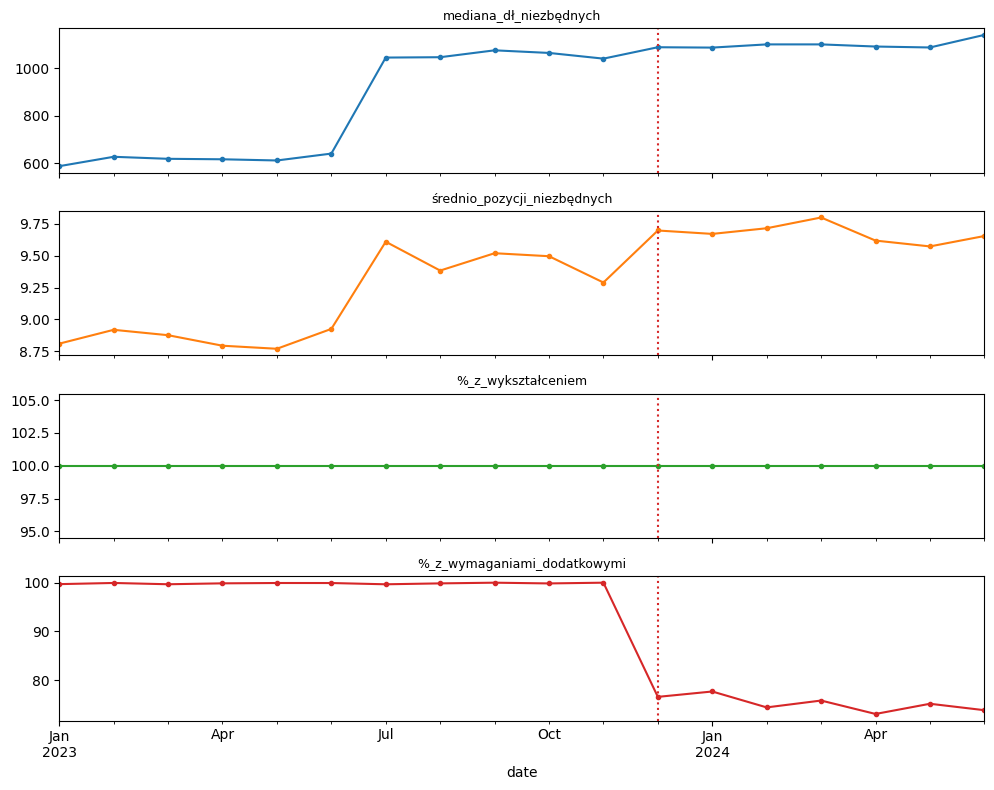

,mediana_dł_niezbędnych,średnio_pozycji_niezbędnych,%_z_wykształceniem,%_z_wymaganiami_dodatkowymi
date,,,,
2023-01-01,588.0,8.8,100.0,99.7
2023-02-01,627.5,8.9,100.0,99.9
2023-03-01,619.0,8.9,100.0,99.7
2023-04-01,617.0,8.8,100.0,99.9
2023-05-01,612.0,8.8,100.0,99.9
2023-06-01,641.0,8.9,100.0,99.9
2023-07-01,1045.5,9.6,100.0,99.7
2023-08-01,1047.0,9.4,100.0,99.9
2023-09-01,1076.0,9.5,100.0,100.0


In [10]:
b = df[(df["date"] >= "2023-01-01") & (df["date"] < "2024-07-01")].set_index("date")
fmt = pd.DataFrame({
    "mediana_dł_niezbędnych": b["ad_requirements1"].str.len().resample("MS").median(),
    "średnio_pozycji_niezbędnych": b["ad_requirements1"].apply(lambda t: len(split_items(t))).resample("MS").mean(),
    "%_z_wykształceniem": b["ad_education"].notna().resample("MS").mean() * 100,
    "%_z_wymaganiami_dodatkowymi": b["ad_requirements2"].notna().resample("MS").mean() * 100,
})
axes = fmt.plot(subplots=True, marker=".", figsize=(10, 8), legend=False)
for ax, name in zip(axes, fmt.columns):
    ax.set_title(name, fontsize=9)
    ax.axvline(SOURCE_SWITCH, color="tab:red", ls=":")
plt.tight_layout()
plt.savefig(OUT / "granica_zrodel.png", dpi=120)
plt.show()
fmt.round(1)

## Słowa kluczowe

In [11]:
terms = {
    "AI": r"sztuczn\w* inteligencj|(?-i:\bAI\b)|chat ?gpt|generatywn|model\w* językow|\bLLM",
    "ML / data science": r"uczeni\w* maszynow|machine learning|data scien|deep learning|sieci\w* neuronow",
    "programowanie": r"\bpython\b|\bjava\b|\bc#|javascript|programowani|\bsql\b",
    "analiza danych / BI": r"power ?bi|tableau|analiz\w* danych|hurtowni\w* danych|big data",
    "MS Office": r"ms office|microsoft office|pakiet\w* (ms )?office|\bexcel",
    "obsługa komputera": r"obsług\w* komputer|edytor\w* tekstu|arkusz\w* kalkulacyjn",
    "komunikacja": r"komunikac|komunikatywn",
    "współpraca / zespół": r"prac\w* w zespole|współprac",
    "odporność na stres": r"odporn\w* na stres|pod presją",
    "samodzielność / organizacja": r"samodzieln|organizacj\w* pracy",
    "angielski": r"angielsk",
}

# słowa kluczowe szukam tylko w pozycjach, które nie są formułkami ustawowymi
# (bez zmiany wielkości liter, bo wzorzec "AI" ją rozróżnia)
def substantive(text):
    parts = [p.strip() for p in re.split(SEP, text) if len(p.strip()) > 3]
    return " |-| ".join(p for p in parts if not re.search(BOILERPLATE, p, re.I))

req = (df["ad_requirements1"].fillna("") + " |-| " + df["ad_requirements2"].fillna("")).apply(substantive)
for name, pat in terms.items():
    df[name] = req.str.contains(pat, case=False, regex=True)

share = df.groupby("year")[list(terms)].mean().mul(100).round(2)
share.to_csv(OUT / "slowa_kluczowe_proc.csv")
share.T

C:\Users\patry\AppData\Local\Temp\ipykernel_31408\3343864367.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[name] = req.str.contains(pat, case=False, regex=True)


year,2018,2019,2020,2021,2022,2023,2024,2025,2026
AI,0.00,0.00,0.02,0.00,0.02,0.01,0.07,0.14,0.16
ML / data science,0.01,0.01,0.00,0.02,0.05,0.01,0.01,0.06,0.04
programowanie,4.13,4.07,3.74,4.01,3.80,3.67,3.47,3.63,3.83
analiza danych / BI,0.85,1.06,0.94,1.28,0.90,1.12,1.31,1.46,1.03
MS Office,29.43,31.85,31.78,33.47,33.80,35.96,36.14,35.22,35.88
obsługa komputera,47.56,47.52,45.30,43.97,46.89,44.15,42.22,41.85,40.31
komunikacja,63.64,60.28,57.08,61.14,57.75,62.23,63.01,63.50,63.20
współpraca / zespół,45.23,43.98,46.47,49.76,47.71,49.56,50.72,54.27,55.36
odporność na stres,18.76,18.46,20.15,17.77,16.22,17.27,15.64,16.31,17.22
samodzielność / organizacja,37.97,38.07,34.40,40.58,38.98,41.32,43.73,44.84,44.32


In [12]:
df.groupby("year")[list(terms)].sum().T

year,2018,2019,2020,2021,2022,2023,2024,2025,2026
AI,0,0,2,0,4,1,10,17,15
ML / data science,2,1,0,4,11,2,1,8,4
programowanie,806,744,489,670,831,602,487,457,359
analiza danych / BI,167,193,123,214,196,183,183,184,97
MS Office,5749,5822,4156,5595,7397,5896,5067,4430,3365
obsługa komputera,9291,8686,5925,7350,10263,7239,5919,5264,3780
komunikacja,12433,11018,7465,10220,12640,10203,8835,7988,5927
współpraca / zespół,8835,8038,6078,8319,10442,8126,7112,6827,5192
odporność na stres,3664,3374,2636,2970,3549,2832,2193,2052,1615
samodzielność / organizacja,7418,6958,4499,6784,8532,6774,6131,5640,4156


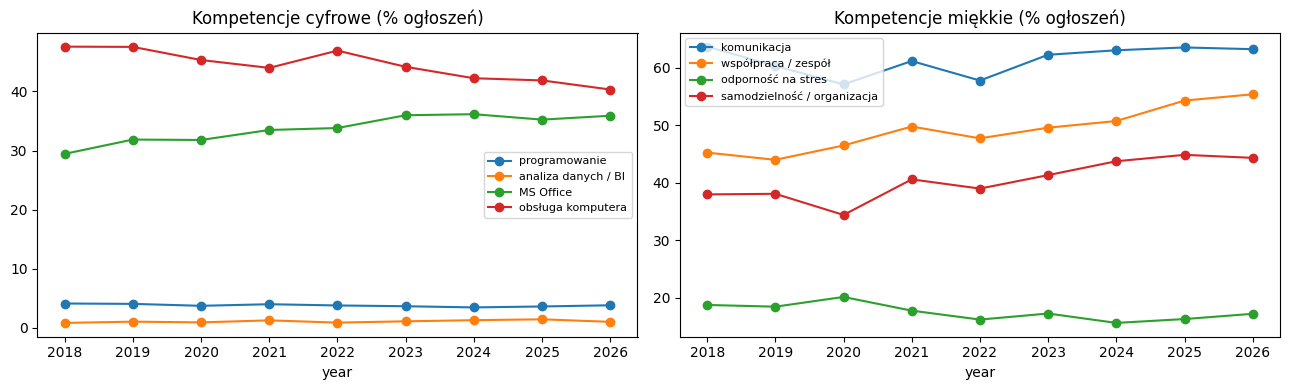

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
share[["programowanie", "analiza danych / BI", "MS Office", "obsługa komputera"]].plot(
    ax=axes[0], marker="o", title="Kompetencje cyfrowe (% ogłoszeń)")
share[["komunikacja", "współpraca / zespół", "odporność na stres", "samodzielność / organizacja"]].plot(
    ax=axes[1], marker="o", title="Kompetencje miękkie (% ogłoszeń)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "slowa_kluczowe.png", dpi=120)
plt.show()

### Ogłoszenia z AI

In [14]:
pat = re.compile(terms["AI"], flags=re.I)

def context(text, width=100):
    m = pat.search(text)
    return text[max(0, m.start() - width): m.end() + width] if m else ""

ai = df[df["AI"]].copy()
ai["kontekst"] = req[ai.index].apply(context)
print(len(ai), "z", len(df))
ai[["ad_id", "date", "ad_job_title", "ad_institution", "kontekst"]].sort_values("date")

49 z 141868


,ad_id,date,ad_job_title,ad_institution,kontekst
42422,62074,2020-03-06,starszy specjalista,Ministerstwo Cyfryzacji w Warszawie,"doświadczenie zawodowe: co najmniej 2 lata w obszarze związanym z nowymi technologiami (AI, IoT, blockchain) |-| znajomość języka angielskiego na ..."
42839,62507,2020-03-17,naczelnik wydziału,Kancelaria Prezesa Rady Ministrów w Warszawie,"nku GovTech w Europie i na świecie, rynku nowoczesnych technologii w Polsce, podstaw funkcjonowania sztucznej inteligencji i jej zastosowań w funk..."
71357,92332,2022-02-04,specjalista,Ministerstwo Finansów w Warszawie,"w zespole |-| Wykształcenie: wyższe uzupełnione o studia podyplomowe z dziedziny analiz – Big Data, sztucznej inteligencji - AI, Data Science |-| ..."
76285,97433,2022-04-22,radca,Główny Urząd Miar w Warszawie,doświadczenie zawodowe: co najmniej 5 lat w tworzeniu aplikacji z wykorzystaniem sztucznej inteligencji |-| znajomość języka angielskiego na pozio...
76462,97616,2022-05-05,metrolog,Główny Urząd Miar w Warszawie,"informacyjno-pomiarowych lub w prowadzeniu prac badawczo-rozwojowych, w szczególności w dziedzinie sztucznej inteligencji lub w realizacji projek..."
79781,101077,2022-06-22,metrolog,Główny Urząd Miar w Warszawie,"informacyjno-pomiarowych lub w prowadzeniu prac badawczo-rozwojowych, w szczególności w dziedzinie sztucznej inteligencji lub w realizacji projek..."
104668,127114,2023-09-14,informatyk,Urząd Statystyczny w Białymstoku,"ie zawodowe: na stanowisku programisty |-| znajomość zagadnień z dziedziny Data Science – Big Data, sztuczna inteligencja, Machine Learning, Deep ..."
139087,136584,2024-04-19,naczelnik wydziału,Ministerstwo Cyfryzacji w Warszawie,"Doświadczenie zawodowe powyżej 4 lat w zakresie nowych technologii, w tym sztucznej inteligencji, w tym co najmniej 1 rok w jednostkach sektora fi..."
139877,137391,2024-05-09,starszy specjalista,Ministerstwo Cyfryzacji w Warszawie,ora finansów publicznych w obszarze technologii przełomowych |-| Znajomość: projektu rozporządzenia AI Act |-| „Polityki dla rozwoju sztucznej int...
141500,139051,2024-06-19,specjalista,Ministerstwo Edukacji Narodowej w Warszawie,iej 1 rok w administracji publiczne |-| Szkolenia z komunikacji wewnętrznej |-| Szkolenia z zakresu AI – sztucznej inteligencji |-| Szkolenia z za...


## Skok współpracy w 2023

Udział ogłoszeń ze współpracą / pracą w zespole rośnie w 2023 o kilkanaście punktów, a w tym samym roku rośnie mediana długości wymagań niezbędnych. Sprawdzam miesięcznie, czy to zmiana stopniowa, czy nagły skok (np. nowy formularz).

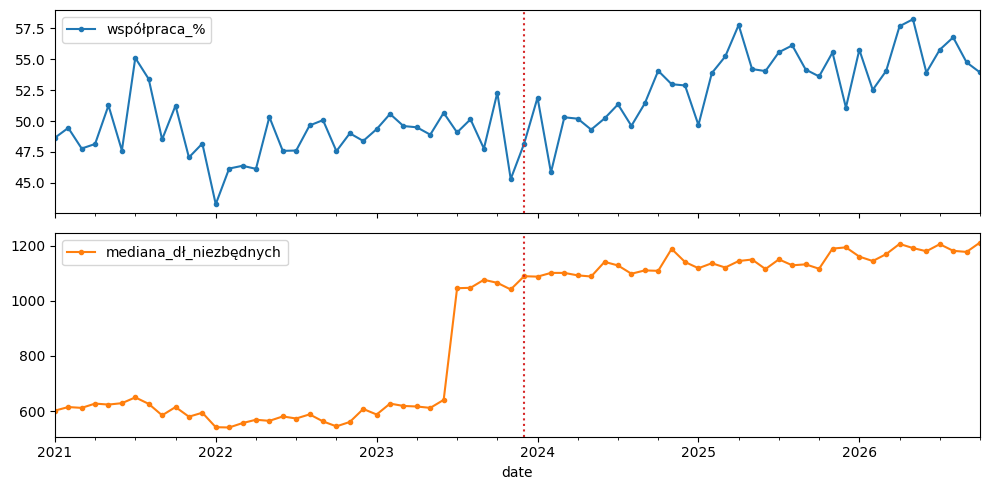

In [15]:
m = df[df["date"] >= "2021-01-01"].set_index("date")
monthly_check = pd.DataFrame({
    "współpraca_%": m["współpraca / zespół"].resample("MS").mean() * 100,
    "mediana_dł_niezbędnych": m["ad_requirements1"].str.len().resample("MS").median(),
})
axes = monthly_check.plot(subplots=True, marker=".", figsize=(10, 5))
for ax in axes:
    ax.axvline(SOURCE_SWITCH, color="tab:red", ls=":")
plt.tight_layout()
plt.show()

In [16]:
# które pozycje wymagań najbardziej zyskały w 2023 względem 2022
it = df[df["year"].isin([2022, 2023])][["year", "ad_requirements1"]].copy()
it["item"] = it["ad_requirements1"].apply(split_items)
it = it.explode("item").drop_duplicates()
freq = it.groupby(["item", "year"]).size().unstack(fill_value=0)
freq = freq.div(df["year"].value_counts()[[2022, 2023]]).mul(100)
freq["zmiana_pp"] = freq[2023] - freq[2022]
freq.sort_values("zmiana_pp", ascending=False).head(15).round(2)

year,2022,2023,zmiana_pp
item,,,
"w służbie cywilnej nie może być zatrudniona osoba, która w okresie od dnia 22 lipca 1944 r. do dnia 31 lipca 1990 r. pracowała lub pełniła służbę w organach bezpieczeństwa państwa lub była współpracownikiem tych organów w rozumieniu przepisów ustawy z dnia 18 października 2006 r. o ujawnianiu informacji o dokumentach organów bezpieczeństwa państwa z lat 1944–1990 oraz treści tych dokumentów - nie dotyczy kandydatek/kandydatów urodzonych 1 sierpnia 1972 r. lub później. osoba wybrana do zatrudnienia będzie musiała złożyć oświadczenie lustracyjne, jeśli urodziła się przed 1 sierpnia 1972 r",0.00,11.74,11.74
nieskazanie prawomocnym wyrokiem za umyślne przestępstwo lub umyślne przestępstwo skarbowe,51.48,62.93,11.46
korzystanie z pełni praw publicznych,51.48,62.93,11.46
posiadanie obywatelstwa polskiego,50.08,61.35,11.27
komunikatywność,6.49,9.16,2.66
umiejętność pracy w zespole,5.40,7.06,1.66
umiejętność analitycznego myślenia,2.16,3.61,1.45
"w służbie cywilnej nie może być zatrudniona osoba, która w okresie od dnia 22 lipca 1944 r. do dnia 31 lipca 1990 r. pracowała lub pełniła służbę w organach bezpieczeństwa państwa lub była współpracownikiem tych organów w rozumieniu przepisów ustawy z dnia 18 października 2006 r. o ujawnianiu informacji o dokumentach organów bezpieczeństwa państwa z lat 1944–1990 oraz treści tych dokumentów - nie dotyczy kandydatek/kandydatów urodzonych 1 sierpnia 1972 r. lub później",0.00,0.95,0.95
znajomość ustawy o służbie cywilnej,2.78,3.57,0.79


In [17]:
# czy wzrost jest też w obrębie tych samych stanowisk? (żeby wykluczyć zmianę struktury ofert)
top = df["ad_job_title"].str.lower().value_counts().head(10).index
(df[df["ad_job_title"].str.lower().isin(top)]
   .groupby([df["ad_job_title"].str.lower(), "year"])["współpraca / zespół"].mean()
   .mul(100).round(1).unstack().loc[:, 2021:])

year,2021,2022,2023,2024,2025
ad_job_title,,,,,
główny specjalista,67.7,62.7,64.0,70.4,73.8
inspektor,52.3,50.9,48.2,49.3,52.1
inspektor weterynaryjny,33.3,38.1,30.6,27.9,30.7
inspektor wojewódzki,37.4,41.4,46.5,48.2,49.9
referendarz,56.5,57.7,62.6,65.2,69.1
referent,26.7,21.1,26.9,27.7,33.3
specjalista,65.9,64.2,67.4,67.0,68.4
starszy inspektor,59.7,60.8,62.3,60.4,59.0
starszy referent,37.8,36.1,39.8,35.5,37.4


## Stanowiska i urzędy

### Ile jest stanowisk

`ad_job_title` to nazwa stanowiska w służbie cywilnej (np. „specjalista”, „referent”), a nie opis zawodu - czym osoba się zajmuje, mówi `ad_work_place2` („Do spraw”). Od 2024 część nazw ma też formę żeńską po ukośniku („specjalista/specjalistka”), więc do liczenia biorę część przed ukośnikiem.

In [18]:
title = df["ad_job_title"].str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
df["stanowisko"] = title.str.split("/").str[0].str.strip()
counts = df["stanowisko"].value_counts()

print("różnych nazw stanowisk (surowo):", title.nunique())
print("różnych stanowisk po ujednoliceniu form żeńskich:", counts.size)
print("stanowisk z co najmniej 10 ogłoszeniami:", (counts >= 10).sum(), "| z jednym ogłoszeniem:", (counts == 1).sum())
print("ile stanowisk obejmuje 80% ogłoszeń:", (counts.cumsum() / counts.sum() < 0.8).sum() + 1)

pd.DataFrame({
    "ogłoszeń": df.groupby("year").size(),
    "różnych stanowisk": df.groupby("year")["stanowisko"].nunique(),
})

różnych nazw stanowisk (surowo): 375
różnych stanowisk po ujednoliceniu form żeńskich: 244
stanowisk z co najmniej 10 ogłoszeniami: 162 | z jednym ogłoszeniem: 32
ile stanowisk obejmuje 80% ogłoszeń: 15


,ogłoszeń,różnych stanowisk
year,,
2018,19535,177
2019,18277,176
2020,13079,168
2021,16717,164
2022,21887,146
2023,16395,146
2024,14021,159
2025,12579,141
2026,9378,139


In [19]:
df["ad_job_title"].str.lower().str.strip().value_counts().head(15)

ad_job_title
referent                           17960
specjalista                        16065
inspektor                          12006
inspektor weterynaryjny            11775
starszy specjalista                11762
główny specjalista                  8277
starszy inspektor                   6460
inspektor wojewódzki                5374
starszy referent                    5291
referendarz                         3302
młodszy specjalista                 2188
księgowy                            2024
inspektor nadzoru budowlanego       1669
starszy inspektor weterynaryjny     1629
wizytator                           1446
Name: count, dtype: int64

In [20]:
df["ad_institution"].value_counts().head(10)

ad_institution
Izba Administracji Skarbowej w Warszawie         7433
Generalna Dyrekcja Dróg Krajowych i Autostrad    5160
Izba Administracji Skarbowej w Poznaniu          2465
Ministerstwo Finansów w Warszawie                2169
Dolnośląski Urząd Wojewódzki we Wrocławiu        2127
Izba Administracji Skarbowej w Gdańsku           2099
Izba Administracji Skarbowej we Wrocławiu        2005
Mazowiecki Urząd Wojewódzki w Warszawie          1928
Łódzki Urząd Wojewódzki w Łodzi                  1860
Izba Administracji Skarbowej w Krakowie          1758
Name: count, dtype: int64

In [21]:
it_title = df["ad_job_title"].str.contains(r"informaty|programist|analityk|danych|teleinform|cyber", case=False)
it_title.groupby(df["year"]).mean().mul(100).round(2)

year
2018    1.96
2019    1.61
2020    1.12
2021    0.98
2022    1.00
2023    0.87
2024    0.94
2025    0.93
2026    0.77
Name: ad_job_title, dtype: float64

## Notatki

Dane po dołączeniu 2024-2026 (stan z 15.10.2026):
- Nasze pobranie: 36 419 ogłoszeń z datami 14.12.2023-15.10.2026, numery ciągłe od 131 558 do 169 075 (bez luk). Z RepOD pokrywa się jedno `ad_id`.
- RepOD ma pod koniec mało ogłoszeń: XI 2023 - 532, XII 2023 - 25 (wcześniej ok. 1300-1800 miesięcznie), więc XI-XII 2023 są niepełne. X 2026 jest niepełny (dane do 15.10). Liczby roczne dla 2023 i 2026 nie są porównywalne z innymi latami, udziały procentowe tak.
- Wzorzec „współpraca / zespół” łapał formułkę lustracyjną „…współpracy z organami bezpieczeństwa państwa”, a `BOILERPLATE` znał tylko odmianę „organach”. Formułka z tym sformułowaniem jest w ok. 9-15% ogłoszeń w latach 2018-2022, 39% w 2023 i 80-89% w 2024-2026. Teraz formułki są pomijane przy liczeniu pozycji i słów kluczowych; bez nich „współpraca / zespół” to ok. 44-50% w 2018-2022, 50% w 2023 i 51-55% w 2024-2026.
- Formularz ogłoszenia: `template` v7 - 29 775, v8 - 6 644 (tylko w naszym pobraniu). Zmiany na granicy źródeł sprawdza sekcja „Zgodność formatu”.

Notatki dla 2018-2023 (RepOD):
- 107 260 wierszy, 46 zduplikowanych `ad_id`. Daty od 18.11.2017 do 15.12.2023, rok 2017 pominięty (tylko 1,5 miesiąca).
- Liczba ogłoszeń: ok. 18-20 tys. rocznie, spadek w 2020 (pandemia), najwięcej w 2022.
- Pozycje w tekstach są rozdzielone `|-|`. `ad_requirements1` = wymagania niezbędne, `ad_requirements2` = dodatkowe.
- AI pojawia się w 7 ogłoszeniach na ok. 107 tys., wszystkie to stanowiska eksperckie/techniczne (MC, KPRM, MF, GUM, US). Do grudnia 2023 nie ma ani jednego ogłoszenia z ChatGPT ani GenAI.
- MS Office rośnie (ok. 29% → 36%), ogólna „obsługa komputera” spada (ok. 46% → 40%).
- Współpraca / praca w zespole: ok. 55% w latach 2020-2022, ok. 71% w 2023 (liczone jeszcze z formułką lustracyjną, zob. wyżej). Jednocześnie mediana długości wymagań niezbędnych rośnie z 565 do 763 znaków. Do wyjaśnienia (sekcja wyżej), czy to zmiana formularza.
- Formuła „Kompetencje miękkie:” prawie nie występuje do 2023 (<1%), pojawia się dopiero w nowszych ogłoszeniach - ważne przy dołączaniu danych z 2024-2026.
- Stanowiska IT to ok. 1-2% ogłoszeń i ich udział spada.
- Liczba pozycji wymagań po poprawce separatora: (uzupełnić)